In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
def calc_rms (data_set):
    sum_of_squares = 0
    for i in range(0,len(data_set)):
        sum_of_squares = sum_of_squares + data_set[i]**2
    rms = np.sqrt(sum_of_squares/len(data_set))
    return rms

def calc_rms_error (predicted_data, obsv_data):
    sum_of_squares_of_error = 0
    if len(predicted_data) != len(obsv_data):
        print ('Warning! Data Sets of Unequal Size! Calculation is invalid!')
    for i in range(0,len(predicted_data)):
        sum_of_squares_of_error = sum_of_squares_of_error + (predicted_data[i] - obsv_data[i])**2
    ms_error = sum_of_squares_of_error/len(predicted_data)
    rms_error = np.sqrt(ms_error)
    return rms_error
    
lum_limits=(2.8,4.5)
per_limits=(1.2,3)
mass_limits=(np.log(0.5),np.log(5))
Q_limits=(-0.65,1.45)
mdot_limits=(-9,-4)
resid_limits=(-3,3)

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0)))
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0)))
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0)))
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0)))

In [4]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [5]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

In [6]:
array_to_sort = np.stack((logMData, logRData, logLData, logPData, logMdotData, logTeffObsvData, logTeffCalcData, logMdotperMData))

MdotIndex_sorting=4
LIndex_sorting=2
PIndex_sorting=3
MIndex_sorting=0
RIndex_sorting=1
TeffObsvIndex_sorting=5
TeffCalcIndex_sorting=6
MdotperMIndex_sorting=7

In [7]:
def CriticalZoneOnly (DataToTrim,logLowerBound,logUpperBound): # Function to restrict an imported data set
    # to only stars in the critical mass loss range
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(DataToTrim)
    while i<len(DataToTrim[MdotIndex]):
        if np.log10(DataToTrim[MdotIndex][i]) < logLowerBound: # If logMdot is lesser than the declared lower bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        elif np.log10(DataToTrim[MdotIndex][i]) > logUpperBound: # If logMdot is greater than the declared upper bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        i += 1 # Move to the next row
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)

In [8]:
def examine_index(elem): 
    # Sorting Key. Will sort a list based on the specified index hard coded here.
    return elem[MdotperMIndex_sorting]
def sort_star_data(DataToSort):
    TransposedArray=np.transpose(DataToSort)
    TempList=TransposedArray.tolist()
    TempList=sorted(TempList,key = operator.itemgetter(MdotperMIndex_sorting))
    return np.transpose(np.asarray(TempList))

In [9]:
sort_star_data(array_to_sort)[-1]

array([-8.20808822, -8.1602302 , -8.15888236, ..., -5.42038435,
       -5.38015707, -5.3440409 ])

In [10]:
def MassRangeSelect (DataToTrim, LowerBound, UpperBound ):
    return np.transpose(np.transpose(sort_star_data(DataToTrim))[LowerBound-1:UpperBound-1])

In [11]:
MassRangeSelect (DataToFit,780,1171)

array([[           nan,            nan,            nan, ...,
                   nan,            nan,            nan],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [6.90000000e-11, 6.90000000e-11, 6.90000000e-11, ...,
        3.20000000e-11, 1.60000000e-10, 4.80000000e-11],
       ...,
       [8.03000000e+00, 6.33000000e+00, 5.41000000e+00, ...,
        1.88000000e+00, 1.89000000e+00, 4.89000000e+00],
       [1.29820429e+00, 2.00739185e+00, 1.62239232e+00, ...,
        1.88074803e+00, 2.05755203e+00, 1.97419923e+00],
       [2.10945573e+02, 2.14691383e+02, 2.29331719e+02, ...,
        1.97870252e+02, 2.35905703e+02, 1.85255559e+02]])

# (P/L^W), M fits

## M0 Stars

In [12]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)

logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

DataToFit = np.stack((logMData, logRData, logLData, logPData, logMdotData, logTeffObsvData, logTeffCalcData, logMdotperMData))

MdotIndex_sorting=4
LIndex_sorting=2
PIndex_sorting=3
MIndex_sorting=0
RIndex_sorting=1
TeffObsvIndex_sorting=5
TeffCalcIndex_sorting=6
MdotperMIndex_sorting=7

DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = DataToFit[MIndex_sorting]
logRData = DataToFit[RIndex_sorting]
logLData = DataToFit[LIndex_sorting]
logPData = DataToFit[PIndex_sorting]
logMdotperMData = DataToFit[MdotperMIndex_sorting]
logTeffObsvData = DataToFit[TeffObsvIndex_sorting]
logTeffCalcData = DataToFit[TeffCalcIndex_sorting]

40th Percentile: 780 60th Percentile: 1171


In [13]:
# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.795
Model:                            WLS   Adj. R-squared:                  0.794
Method:                 Least Squares   F-statistic:                     1506.
Date:                Wed, 21 Oct 2020   Prob (F-statistic):          7.80e-136
Time:                        15:22:40   Log-Likelihood:                 565.22
No. Observations:                 391   AIC:                            -1126.
Df Residuals:                     389   BIC:                            -1119.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3198      0.066     -4.852      0.0

In [14]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex_sorting]/DataToFit[LIndex_sorting]**WRatio)) # log (P/(L^W))

W= 0.7149885514131027


logP= -0.3197733472645938 + 0.7149885514131027 logL


Text(0.5, 1.0, 'M0 - logP = V + W logL')

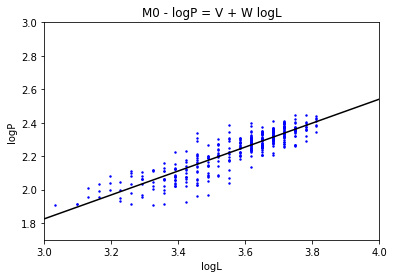

In [15]:
print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([3,3.5,4])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.7, 3)
plot.title('M0 - logP = V + W logL')

In [16]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [17]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.206
Model:                            WLS   Adj. R-squared:                  0.206
Method:                 Least Squares   F-statistic:                     253.3
Date:                Wed, 21 Oct 2020   Prob (F-statistic):           1.70e-98
Time:                        15:22:40   Log-Likelihood:                -711.19
No. Observations:                1951   AIC:                             1428.
Df Residuals:                    1948   BIC:                             1445.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.9020      0.041   -142.688      0.0

In [18]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

Beta: [14.9006324   8.33690167 -1.99869772]
Beta Std Error: [0.74755444 0.47360457 0.24016239]
Beta Covariance: [[222.24471473 131.59598888  71.16289066]
 [131.59598888  89.2026093   41.99978343]
 [ 71.16289066  41.99978343  22.93801188]]
Residual Variance: 0.002514514892237477
Inverse Condition #: 0.015139975316075123
Reason(s) for Halting:
  Sum of squares convergence


In [19]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

logMdot = 14.900632397316116 log(P/L^W) +  8.33690166903896 logM +  -1.9986977238946124


In [20]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.11123582570204064 ) + ( 0.9835833728277326 )*logMdot_obsv


Text(0.5, 1.0, 'M0 - No Errors Included')

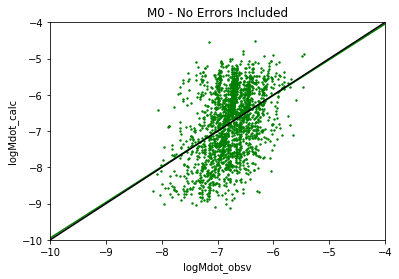

In [21]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('M0 - No Errors Included')

### Residuals

In [22]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'M0'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [23]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

Residual Fit: logMdotCalc-logMdotObsv = -12.758282980649778 + 5.813426121596799 logP


#### Plot Set: NewlogMdotCalc - logMdotobs vs logP, logL, logQ, and logM

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -12.758282980649778 + 5.813426121596799 logP


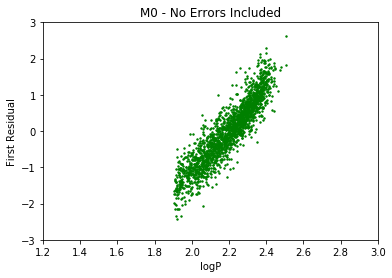

In [24]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -12.153357505939782 + 3.4454404907888097 logL


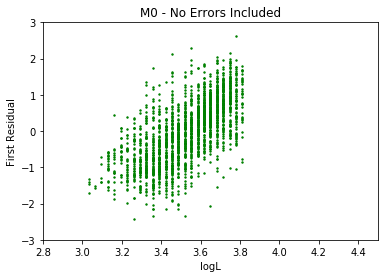

In [25]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.691796933764117 + 5.167238076745 logQx


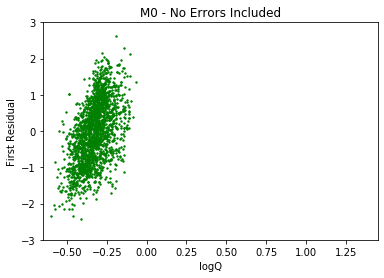

In [26]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQx')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.018345983024411133 + 1.5071241259682884 logM


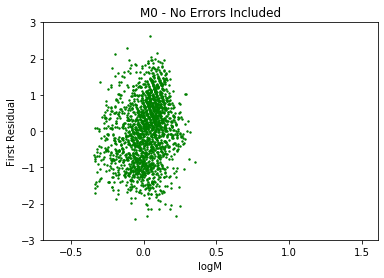

In [27]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logM')

In [28]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

NewMdotCalc = 10.759585256755166 + 14.900632397316116 log(P/L^W) +  8.33690166903896 logM -  5.813426121596799 logP ; W = 0.7149885514131027
NewMdotCalc = 10.759585256755166 + ( 9.087206275719318 ) logP + ( -10.653781572896197 ) logL +  8.33690166903896 logM


NewMdotCalc Fit: NewlogMdotCalc = -5.090020638133114 + 0.24879472214992088 logMdot_obsv


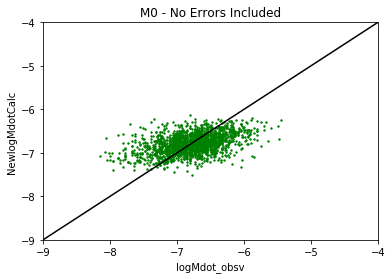

In [29]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/newMdot_vs_Mdotobsv')

Residuals Fit: OldResidual = 4.228136412081501e-08 + 1.0000000000000049 NewResidual


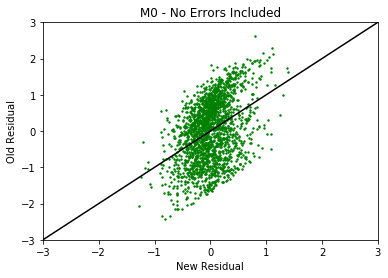

In [30]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_second_resid')

In [31]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

RMS Error: 0.3539340105648962
STD Dev: 0.22006589174734087


#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [32]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 5.595567412197688e-15 + 6.130838024753782e-15 logP


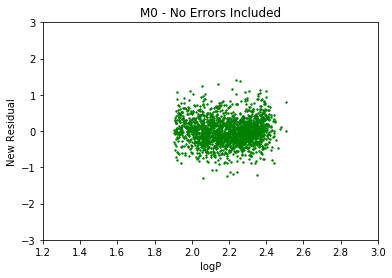

In [33]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.8321983250669609 + -0.23592573444627576 logL


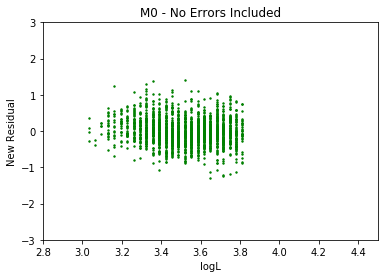

In [34]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.20863544031267697 + 0.6372331080459527 logQ


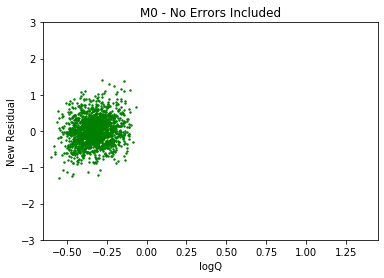

In [35]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.006137038237853262 + -0.5041570714125894 logM


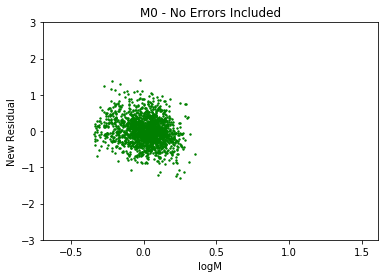

In [36]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logM')

## M1 Stars

In [37]:
DataToFit=M1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)

logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

DataToFit = np.stack((logMData, logRData, logLData, logPData, logMdotData, logTeffObsvData, logTeffCalcData, logMdotperMData))

MdotIndex_sorting=4
LIndex_sorting=2
PIndex_sorting=3
MIndex_sorting=0
RIndex_sorting=1
TeffObsvIndex_sorting=5
TeffCalcIndex_sorting=6
MdotperMIndex_sorting=7

DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = DataToFit[MIndex_sorting]
logRData = DataToFit[RIndex_sorting]
logLData = DataToFit[LIndex_sorting]
logPData = DataToFit[PIndex_sorting]
logMdotperMData = DataToFit[MdotperMIndex_sorting]
logTeffObsvData = DataToFit[TeffObsvIndex_sorting]
logTeffCalcData = DataToFit[TeffCalcIndex_sorting]

40th Percentile: 865 60th Percentile: 1298


In [38]:
# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.887
Model:                            WLS   Adj. R-squared:                  0.887
Method:                 Least Squares   F-statistic:                     3394.
Date:                Wed, 21 Oct 2020   Prob (F-statistic):          1.95e-206
Time:                        15:22:42   Log-Likelihood:                 692.49
No. Observations:                 433   AIC:                            -1381.
Df Residuals:                     431   BIC:                            -1373.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1366      0.036     -3.805      0.0

In [39]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex_sorting]/DataToFit[LIndex_sorting]**WRatio)) # log (P/(L^W))

W= 0.5789680768583638


logP= -0.13661655218968616 + 0.5789680768583638 logL


Text(0.5, 1.0, 'M1 - logP = V + W logL')

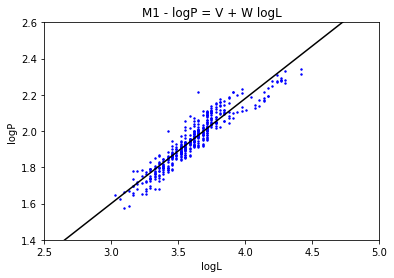

In [40]:
print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([2.5,3.5,4,5])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.4, 2.6)
plot.title('M1 - logP = V + W logL')

In [41]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=M1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [42]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.343
Model:                            WLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     563.4
Date:                Wed, 21 Oct 2020   Prob (F-statistic):          1.31e-197
Time:                        15:22:42   Log-Likelihood:                -855.24
No. Observations:                2162   AIC:                             1716.
Df Residuals:                    2159   BIC:                             1734.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.3483      0.020   -319.778      0.0

In [43]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

Beta: [nan nan nan]
Beta Std Error: [0. 0. 0.]
Beta Covariance: [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Residual Variance: 0.0
Inverse Condition #: nan
Reason(s) for Halting:
  Numerical error detected


In [44]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

logMdot = nan log(P/L^W) +  nan logM +  nan


In [45]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

ValueError: zero-size array to reduction operation maximum which has no identity

In [ ]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('M1 - No Errors Included')

### Residuals

In [ ]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'M1'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

#### Plot Set: NewlogMdotCalc - logMdotobs vs logP, logL, logQ, and logM

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQx')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logM')

In [ ]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

In [ ]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/newMdot_vs_Mdotobsv')

In [ ]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_second_resid')

In [ ]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [ ]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logM')

## C0 Stars

In [ ]:
DataToFit=C0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)

logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

DataToFit = np.stack((logMData, logRData, logLData, logPData, logMdotData, logTeffObsvData, logTeffCalcData, logMdotperMData))

MdotIndex_sorting=4
LIndex_sorting=2
PIndex_sorting=3
MIndex_sorting=0
RIndex_sorting=1
TeffObsvIndex_sorting=5
TeffCalcIndex_sorting=6
MdotperMIndex_sorting=7

DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = DataToFit[MIndex_sorting]
logRData = DataToFit[RIndex_sorting]
logLData = DataToFit[LIndex_sorting]
logPData = DataToFit[PIndex_sorting]
logMdotperMData = DataToFit[MdotperMIndex_sorting]
logTeffObsvData = DataToFit[TeffObsvIndex_sorting]
logTeffCalcData = DataToFit[TeffCalcIndex_sorting]

In [ ]:
# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

In [ ]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex_sorting]/DataToFit[LIndex_sorting]**WRatio)) # log (P/(L^W))

In [ ]:
print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([2.5,3.5,4,5])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(2, 3.2)
plot.title('C0 - logP = V + W logL')

In [ ]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=C0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [ ]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

In [ ]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

In [ ]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [ ]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('C0 - No Errors Included')

### Residuals

In [ ]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'C0'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

#### Plot Set: NewlogMdotCalc - logMdotobs vs logP, logL, logQ, and logM

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQx')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logM')

In [ ]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

In [ ]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/newMdot_vs_Mdotobsv')

In [ ]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_second_resid')

In [ ]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [ ]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logM')

## C1 Stars

In [ ]:
DataToFit=C1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)

logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

DataToFit = np.stack((logMData, logRData, logLData, logPData, logMdotData, logTeffObsvData, logTeffCalcData, logMdotperMData))

MdotIndex_sorting=4
LIndex_sorting=2
PIndex_sorting=3
MIndex_sorting=0
RIndex_sorting=1
TeffObsvIndex_sorting=5
TeffCalcIndex_sorting=6
MdotperMIndex_sorting=7

DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = DataToFit[MIndex_sorting]
logRData = DataToFit[RIndex_sorting]
logLData = DataToFit[LIndex_sorting]
logPData = DataToFit[PIndex_sorting]
logMdotperMData = DataToFit[MdotperMIndex_sorting]
logTeffObsvData = DataToFit[TeffObsvIndex_sorting]
logTeffCalcData = DataToFit[TeffCalcIndex_sorting]

In [ ]:
# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

In [ ]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex_sorting]/DataToFit[LIndex_sorting]**WRatio)) # log (P/(L^W))

In [ ]:
print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([2.5,3.5,4,5])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(2, 3.2)
plot.title('C1 - logP = V + W logL')

In [ ]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=C1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotperMData = np.log10(DataToFit[MdotIndex]/DataToFit[MIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [ ]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

In [ ]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

In [ ]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [ ]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('C1 - No Errors Included')

### Residuals

In [ ]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'C1'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

#### Plot Set: NewlogMdotCalc - logMdotobs vs logP, logL, logQ, and logM

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQx')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_logM')

In [ ]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

In [ ]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/newMdot_vs_Mdotobsv')

In [ ]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/first_resid_vs_second_resid')

In [ ]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [ ]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

In [ ]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logP')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logL')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logQ')

In [ ]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Qx/'+star_type+'/second_resid_vs_logM')